# Klasifikasi Uang Kertas Rupiah - EfficientNetV2-B0
- Backbone: EfficientNetV2-B0 (Pretrained ImageNet)
- Preprocessing: efficientnet_v2.preprocess_input
- Head: GlobalAvgPool + BatchNorm + Dense(256, L2=1e-4) + Dropout(0.25)
- Fine-Tuning: 40 layer teratas dengan BatchNorm dibekukan (LR=3e-5)
- Class weights otomatis untuk mengatasi ketidakseimbangan sampel
- Evaluasi: Test Accuracy, Macro F1, Confusion Matrix (Fair Comparison)


## 1. Import Library


In [1]:
import os
import sys
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Import helper untuk kompatibilitas Keras / TensorFlow
EfficientNetV2B0 = tf.keras.applications.EfficientNetV2B0
efficientnet_v2 = tf.keras.applications.efficientnet_v2
ImageDataGenerator = tf.keras.preprocessing.image.ImageDataGenerator

print('TensorFlow Version :', tf.__version__)
print('Semua library berhasil di-import.')


TensorFlow Version : 2.20.0
Semua library berhasil di-import.


## 2. Setup Direktori & Parameter Training


In [2]:
# Path direktori dataset dan penyimpanan model lokal
DATASET_BASE = r'C:\DL\rupiah-detector\dataset'
TRAIN_DIR    = os.path.join(DATASET_BASE, 'train')
VAL_DIR      = os.path.join(DATASET_BASE, 'val')
TEST_DIR     = os.path.join(DATASET_BASE, 'test')

MODEL_DIR    = r'C:\DL\rupiah-detector\models'
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_SAVE_PATH    = os.path.join(MODEL_DIR, 'efficientnetv2_frozen.keras')
FINETUNE_SAVE_PATH = os.path.join(MODEL_DIR, 'efficientnetv2_finetuned.keras')
FINAL_MODEL_PATH   = os.path.join(MODEL_DIR, 'efficientnetv2_rupiah.keras')

# Parameter Training
IMG_SIZE        = (224, 224)
BATCH_SIZE      = 32
EPOCHS_FROZEN   = 15
EPOCHS_FINETUNE = 20
LR_FROZEN       = 1e-3
LR_FINETUNE     = 3e-5
NUM_CLASSES     = 7
CLASSES         = ['1000', '2000', '5000', '10000', '20000', '50000', '100000']
SEED            = 42

print('Path Dataset       :', DATASET_BASE)
print('Path Output Model  :', MODEL_DIR)
print('Kelas Nominal (7)  :', CLASSES)
print(f'Ukuran Gambar: {IMG_SIZE}, Batch Size: {BATCH_SIZE}, Epoch: {EPOCHS_FROZEN} (Tahap 1) + {EPOCHS_FINETUNE} (Tahap 2)')


Path Dataset       : C:\DL\rupiah-detector\dataset
Path Output Model  : C:\DL\rupiah-detector\models
Kelas Nominal (7)  : ['1000', '2000', '5000', '10000', '20000', '50000', '100000']
Ukuran Gambar: (224, 224), Batch Size: 32, Epoch: 15 (Tahap 1) + 20 (Tahap 2)


## 3. Distribusi Data per Kelas


In [3]:
def count_images(split_dir):
    counts = {}
    for cls in CLASSES:
        cls_path = os.path.join(split_dir, cls)
        counts[cls] = len(list(pathlib.Path(cls_path).glob('*.jpg'))) if os.path.isdir(cls_path) else 0
    return counts

train_counts = count_images(TRAIN_DIR)
val_counts   = count_images(VAL_DIR)
test_counts  = count_images(TEST_DIR)

df_summary = pd.DataFrame({'Train': train_counts, 'Val': val_counts, 'Test': test_counts})
df_summary['Total'] = df_summary.sum(axis=1)
print('Distribusi jumlah gambar per split:')
display(df_summary)
print(f'Total sampel: Train={df_summary["Train"].sum()}, Val={df_summary["Val"].sum()}, Test={df_summary["Test"].sum()}')


Distribusi jumlah gambar per split:


,Train,Val,Test,Total
1000,130,15,21,166
2000,127,27,24,178
5000,111,26,30,167
10000,111,22,23,156
20000,135,29,25,189
50000,149,27,26,202
100000,131,30,30,191


Total sampel: Train=894, Val=176, Test=179


### 3.1. Class Weights (Penyeimbang Data)


In [4]:
# Menghitung class weights agar nominal dengan sampel lebih sedikit mendapat bobot proporsional
total_train = sum(train_counts.values())
class_weights = {i: total_train / (NUM_CLASSES * train_counts[cls]) for i, cls in enumerate(CLASSES)}

print('Class weights yang dihitung:')
for i, cls in enumerate(CLASSES):
    print(f'  - Kelas Rp {cls:>6} (index {i}): {class_weights[i]:.4f}')


Class weights yang dihitung:
  - Kelas Rp   1000 (index 0): 0.9824
  - Kelas Rp   2000 (index 1): 1.0056
  - Kelas Rp   5000 (index 2): 1.1506
  - Kelas Rp  10000 (index 3): 1.1506
  - Kelas Rp  20000 (index 4): 0.9460
  - Kelas Rp  50000 (index 5): 0.8571
  - Kelas Rp 100000 (index 6): 0.9749


## 4. Data Preprocessing & Augmentasi


### 4.1. Definisi Augmentasi & Preprocessing


In [5]:
# Preprocessing: efficientnet_v2.preprocess_input (standar EfficientNetV2)
train_datagen = ImageDataGenerator(
    preprocessing_function=efficientnet_v2.preprocess_input,
    rotation_range=10,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.08,
    brightness_range=[0.85, 1.15],
    horizontal_flip=False,
    vertical_flip=False,
    fill_mode='constant',
    cval=0.0
)

val_test_datagen = ImageDataGenerator(
    preprocessing_function=efficientnet_v2.preprocess_input
)
print('Pipeline ImageDataGenerator EfficientNetV2-B0 berhasil dikonfigurasi.')


Pipeline ImageDataGenerator EfficientNetV2-B0 berhasil dikonfigurasi.


### 4.2. Inisialisasi Data Generator (Train, Val, Test)


In [6]:
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', classes=CLASSES, shuffle=True, seed=SEED
)

val_generator = val_test_datagen.flow_from_directory(
    VAL_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', classes=CLASSES, shuffle=False
)

test_generator = val_test_datagen.flow_from_directory(
    TEST_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', classes=CLASSES, shuffle=False
)

print(f'Train generator : {train_generator.samples} gambar, {train_generator.num_classes} kelas, {len(train_generator)} batch') 
print(f'Val generator   : {val_generator.samples} gambar, {val_generator.num_classes} kelas, {len(val_generator)} batch')
print(f'Test generator  : {test_generator.samples} gambar, {test_generator.num_classes} kelas, {len(test_generator)} batch')


Found 894 images belonging to 7 classes.
Found 176 images belonging to 7 classes.
Found 179 images belonging to 7 classes.
Train generator : 894 gambar, 7 kelas, 28 batch
Val generator   : 176 gambar, 7 kelas, 6 batch
Test generator  : 179 gambar, 7 kelas, 6 batch


### 4.3. Visualisasi Sampel Gambar Augmentasi


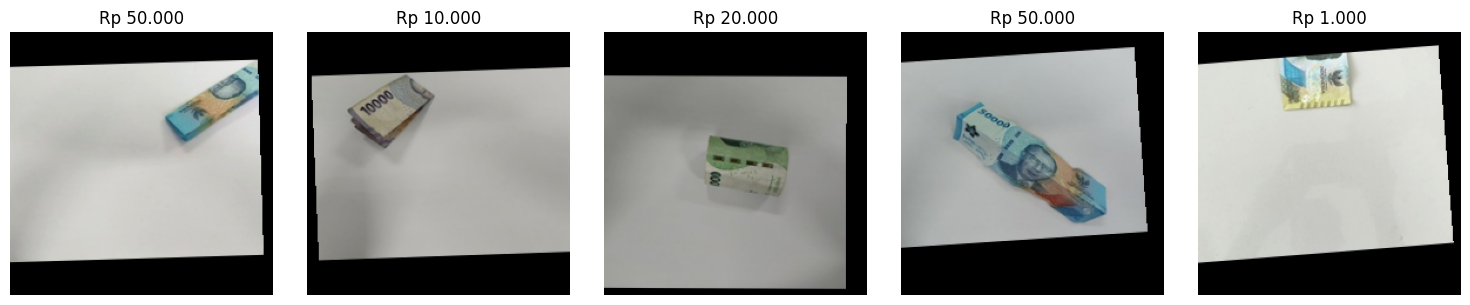

Sampel citra hasil augmentasi training berhasil ditampilkan.


In [7]:
batch_imgs, batch_lbls = next(train_generator)
# Gambar untuk visualisasi (clip ke [0, 255] jika uint8 atau [0, 1] jika float)
disp_imgs = batch_imgs[:5]
if disp_imgs.max() > 1.0:
    disp_imgs = np.clip(disp_imgs / 255.0, 0.0, 1.0)
else:
    disp_imgs = np.clip(disp_imgs, 0.0, 1.0)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i in range(5):
    axes[i].imshow(disp_imgs[i])
    nominal = CLASSES[np.argmax(batch_lbls[i])]
    axes[i].set_title(f'Rp {int(nominal):,}'.replace(',', '.'))
    axes[i].axis('off')
plt.tight_layout()
plt.show()
print('Sampel citra hasil augmentasi training berhasil ditampilkan.')


## 5. Arsitektur Model


### 5.1. Membangun Model Transfer Learning EfficientNetV2-B0


In [8]:
def build_efficientnet_v2(num_classes=7, img_size=(224, 224)):
    inputs = layers.Input(shape=(*img_size, 3), name='rupiah_input')
    base_model = EfficientNetV2B0(
        weights='imagenet',
        include_top=False,
        input_tensor=inputs
    )
    base_model.trainable = False

    x = layers.GlobalAveragePooling2D(name='avg_pool')(base_model.output)
    x = layers.BatchNormalization(name='bn_head')(x)
    x = layers.Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4), name='dense_head')(x)
    x = layers.Dropout(0.25, name='dropout_head')(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='predictions')(x)

    model = models.Model(inputs, outputs, name='EfficientNetV2_B0_Rupiah')
    model.compile(
        optimizer=optimizers.Adam(learning_rate=LR_FROZEN),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model, base_model

model, base_model = build_efficientnet_v2(NUM_CLASSES, IMG_SIZE)
print('Model EfficientNetV2-B0 berhasil dibangun.')
print(f'Total layer: {len(model.layers)}, Base model layer: {len(base_model.layers)}')


24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 41s 2us/step
Model EfficientNetV2-B0 berhasil dibangun.
Total layer: 275, Base model layer: 270


### 5.2. Ringkasan Arsitektur Model (Summary)


In [9]:
model.summary()


Model: "EfficientNetV2_B0_Rupiah"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ rupiah_input        │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ rupiah_input[0][… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          0 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ normalization[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │      4,608 │ stem_activation[… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_bn  │ (None, 112, 112,  │         64 │ block1a_project_… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_ac… │ (None, 112, 112,  │          0 │ block1a_project_… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_conv │ (None, 56, 56,    │      9,216 │ block1a_project_… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_bn   │ (None, 56, 56,    │        256 │ block2a_expand_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_act… │ (None, 56, 56,    │          0 │ block2a_expand_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_co… │ (None, 56, 56,    │      2,048 │ block2a_expand_a… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_bn  │ (None, 56, 56,    │        128 │ block2a_project_… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_conv │ (None, 56, 56,    │     36,864 │ block2a_project_… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_bn   │ (None, 56, 56,    │        512 │ block2b_expand_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_act… │ (None, 56, 56,    │          0 │ block2b_expand_b

 Total params: 6,254,167 (23.86 MB)

 Trainable params: 332,295 (1.27 MB)

 Non-trainable params: 5,921,872 (22.59 MB)

## 6. Training Tahap 1: Classifier Head (Backbone Frozen)


In [10]:
callbacks_stage1 = [
    EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint(MODEL_SAVE_PATH, monitor='val_accuracy', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

print('Memulai Training Tahap 1: Classifier Head (dengan Class Weights)...')
history_stage1 = model.fit(
    train_generator,
    epochs=EPOCHS_FROZEN,
    validation_data=val_generator,
    callbacks=callbacks_stage1,
    class_weight=class_weights,
    verbose=1
)
print('Training Tahap 1 selesai.')
print('Checkpoint model Tahap 1 tersimpan di:', MODEL_SAVE_PATH)


Memulai Training Tahap 1: Classifier Head (dengan Class Weights)...


c:\Users\ASUS TUF\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step - accuracy: 0.5039 - loss: 1.5734
Epoch 1: val_accuracy improved from None to 0.92614, saving model to C:\DL\rupiah-detector\models\efficientnetv2_frozen.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 18s 411ms/step - accuracy: 0.7092 - loss: 0.9082 - val_accuracy: 0.9261 - val_loss: 0.7279 - learning_rate: 0.0010
Epoch 2/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 292ms/step - accuracy: 0.9550 - loss: 0.1845
Epoch 2: val_accuracy improved from 0.92614 to 0.98864, saving model to C:\DL\rupiah-detector\models\efficientnetv2_frozen.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 10s 346ms/step - accuracy: 0.9586 - loss: 0.1661 - val_accuracy: 0.9886 - val_loss: 0.4678 - learning_rate: 0.0010
Epoch 3/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step - accuracy: 0.9796 - loss: 0.1277
Epoch 3: val_accuracy did not improve from 0.98864
28/28 ━━━━━━━━━━━━━━━━━━━━ 9s 335ms/step - accuracy: 0.9799 - loss: 0.1317 - val_accuracy: 0.9830 - val_loss: 0.3641 - learning_rate: 0.0010
Epoch 4/15


## 7. Training Tahap 2: Fine-Tuning


### 7.1. Unfreeze 40 Layer Backbone


In [11]:
# Unfreeze 40 layer teratas, kunci layer BatchNormalization
UNFREEZE_COUNT = 40
base_model.trainable = True

for layer in base_model.layers[:-UNFREEZE_COUNT]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=optimizers.Adam(learning_rate=LR_FINETUNE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

trainable_params = sum(int(np.prod(v.shape)) for v in model.trainable_weights)
print(f'40 layer teratas dibuka (BatchNormalization tetap dibekukan).')
print(f'Jumlah parameter trainable : {trainable_params:,}')
print(f'Learning rate fine-tuning  : {LR_FINETUNE}')


40 layer teratas dibuka (BatchNormalization tetap dibekukan).
Jumlah parameter trainable : 2,040,087
Learning rate fine-tuning  : 3e-05


### 7.2. Eksekusi Training Fine-Tuning


In [12]:
callbacks_stage2 = [
    EarlyStopping(monitor='val_accuracy', patience=6, restore_best_weights=True, verbose=1),
    ModelCheckpoint(FINETUNE_SAVE_PATH, monitor='val_accuracy', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7, verbose=1)
]

print('Memulai Training Tahap 2: Fine-Tuning (dengan Class Weights)...')
history_stage2 = model.fit(
    train_generator,
    epochs=EPOCHS_FINETUNE,
    validation_data=val_generator,
    callbacks=callbacks_stage2,
    class_weight=class_weights,
    verbose=1
)
print('Training Tahap 2 selesai.')
print('Checkpoint model Tahap 2 tersimpan di:', FINETUNE_SAVE_PATH)


Memulai Training Tahap 2: Fine-Tuning (dengan Class Weights)...
Epoch 1/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 328ms/step - accuracy: 0.9873 - loss: 0.0875
Epoch 1: val_accuracy improved from None to 1.00000, saving model to C:\DL\rupiah-detector\models\efficientnetv2_finetuned.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 20s 447ms/step - accuracy: 0.9899 - loss: 0.0846 - val_accuracy: 1.0000 - val_loss: 0.1927 - learning_rate: 3.0000e-05
Epoch 2/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 331ms/step - accuracy: 0.9883 - loss: 0.0883
Epoch 2: val_accuracy did not improve from 1.00000
28/28 ━━━━━━━━━━━━━━━━━━━━ 10s 372ms/step - accuracy: 0.9911 - loss: 0.0820 - val_accuracy: 1.0000 - val_loss: 0.1547 - learning_rate: 3.0000e-05
Epoch 3/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - accuracy: 0.9925 - loss: 0.0765
Epoch 3: val_accuracy did not improve from 1.00000
28/28 ━━━━━━━━━━━━━━━━━━━━ 11s 374ms/step - accuracy: 0.9888 - loss: 0.0807 - val_accuracy: 1.0000 - val_loss: 0.1270 - learning_rate: 3.0000e-05
Epoch 4/2

## 8. Visualisasi Kurva Training


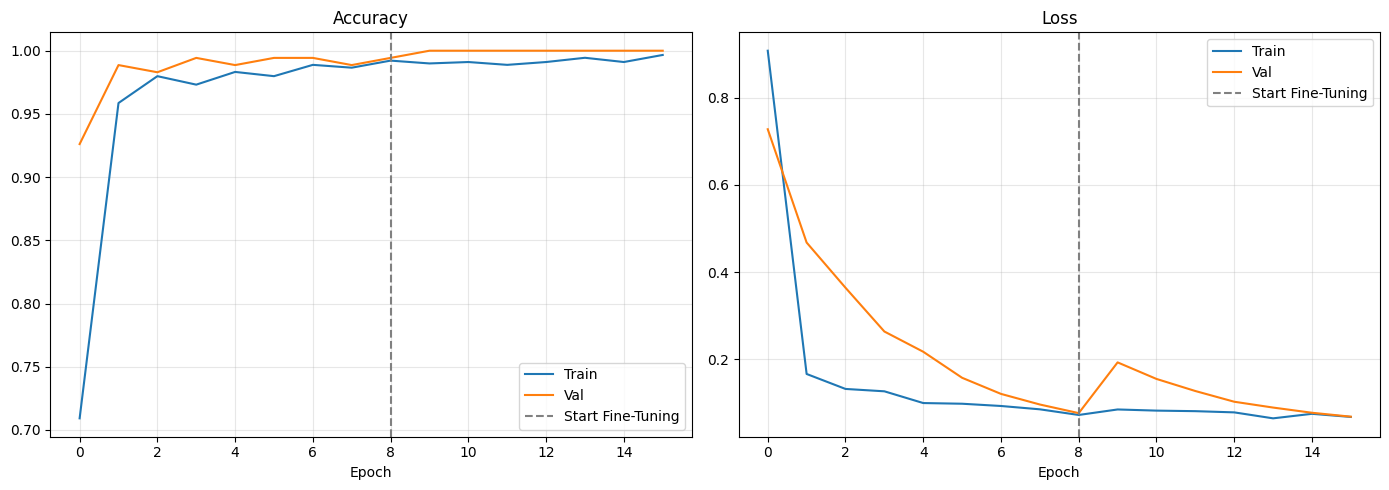

Kurva training (Tahap 1 & 2) berhasil ditampilkan.


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

acc = history_stage1.history['accuracy'] + history_stage2.history['accuracy']
val_acc = history_stage1.history['val_accuracy'] + history_stage2.history['val_accuracy']
loss = history_stage1.history['loss'] + history_stage2.history['loss']
val_loss = history_stage1.history['val_loss'] + history_stage2.history['val_loss']
split_epoch = len(history_stage1.history['accuracy'])

# Plot Akurasi
axes[0].plot(acc, label='Train')
axes[0].plot(val_acc, label='Val')
axes[0].axvline(split_epoch - 1, color='gray', linestyle='--', label='Start Fine-Tuning')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot Loss
axes[1].plot(loss, label='Train')
axes[1].plot(val_loss, label='Val')
axes[1].axvline(split_epoch - 1, color='gray', linestyle='--', label='Start Fine-Tuning')
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print('Kurva training (Tahap 1 & 2) berhasil ditampilkan.')


## 9. Evaluasi Model pada Data Test


### 9.1. Evaluasi Model Tahap 1 (Backbone Frozen)


In [ ]:
model_frozen = tf.keras.models.load_model(MODEL_SAVE_PATH)
test_generator.reset()
probs_frozen = model_frozen.predict(test_generator, verbose=1)
pred_frozen  = np.argmax(probs_frozen, axis=1)
y_true       = test_generator.classes

acc_t1 = accuracy_score(y_true, pred_frozen)
p_t1, r_t1, f1_t1, _ = precision_recall_fscore_support(y_true, pred_frozen, average='macro')

print('=== Hasil Evaluasi Tahap 1 (Backbone Frozen) ===')
print(f'Test Accuracy  : {acc_t1*100:.2f}%')
print(f'Macro Precision: {p_t1:.4f}')
print(f'Macro Recall   : {r_t1:.4f}')
print(f'Macro F1-Score : {f1_t1:.4f}')


6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 492ms/step
=== Hasil Evaluasi Tahap 1 (Backbone Frozen) ===
Test Accuracy  : 99.44%
Macro Precision: 0.9947
Macro Recall   : 0.9938
Macro F1-Score : 0.9941


### 9.2. Evaluasi Model Tahap 2 (Fine-Tuning)


In [ ]:
model_ft = tf.keras.models.load_model(FINETUNE_SAVE_PATH) if os.path.exists(FINETUNE_SAVE_PATH) else model
test_generator.reset()
probs_ft = model_ft.predict(test_generator, verbose=1)
pred_ft  = np.argmax(probs_ft, axis=1)

acc_t2 = accuracy_score(y_true, pred_ft)
p_t2, r_t2, f1_t2, _ = precision_recall_fscore_support(y_true, pred_ft, average='macro')

print('=== Hasil Evaluasi Tahap 2 (Fine-Tuning) ===')
print(f'Test Accuracy  : {acc_t2*100:.2f}%')
print(f'Macro Precision: {p_t2:.4f}')
print(f'Macro Recall   : {r_t2:.4f}')
print(f'Macro F1-Score : {f1_t2:.4f}')


6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 457ms/step
=== Hasil Evaluasi Tahap 2 (Fine-Tuning) ===
Test Accuracy  : 99.44%
Macro Precision: 0.9947
Macro Recall   : 0.9938
Macro F1-Score : 0.9941


### 9.3. Tabel Perbandingan Evaluasi (Tahap 1 vs Tahap 2)


In [16]:
df_metrics = pd.DataFrame({
    'Tahapan': ['Tahap 1 (Backbone Frozen)', 'Tahap 2 (Fine-Tuning)', 'Peningkatan'],
    'Test Accuracy': [f'{acc_t1*100:.2f}%', f'{acc_t2*100:.2f}%', f'+{(acc_t2 - acc_t1)*100:.2f}%'],
    'Macro Precision': [f'{p_t1:.4f}', f'{p_t2:.4f}', f'+{(p_t2 - p_t1):.4f}'],
    'Macro Recall': [f'{r_t1:.4f}', f'{r_t2:.4f}', f'+{(r_t2 - r_t1):.4f}'],
    'Macro F1-Score': [f'{f1_t1:.4f}', f'{f1_t2:.4f}', f'+{(f1_t2 - f1_t1):.4f}']
})
print('Tabel Perbandingan Performa Model:')
display(df_metrics)


Tabel Perbandingan Performa Model:


,Tahapan,Test Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Tahap 1 (Backbone Frozen),99.44%,0.9947,0.9938,0.9941
1,Tahap 2 (Fine-Tuning),99.44%,0.9947,0.9938,0.9941
2,Peningkatan,+0.00%,+0.0000,+0.0000,+0.0000


### 9.4. Classification Report


In [17]:
target_names = [f'Rp {int(c):,}'.replace(',', '.') for c in CLASSES]

print('=== Classification Report - Tahap 1 (Backbone Frozen) ===')
print(classification_report(y_true, pred_frozen, target_names=target_names, digits=4))

print('\n=== Classification Report - Tahap 2 (Fine-Tuning) ===')
print(classification_report(y_true, pred_ft, target_names=target_names, digits=4))


=== Classification Report - Tahap 1 (Backbone Frozen) ===
              precision    recall  f1-score   support

    Rp 1.000     1.0000    1.0000    1.0000        21
    Rp 2.000     1.0000    1.0000    1.0000        24
    Rp 5.000     1.0000    1.0000    1.0000        30
   Rp 10.000     1.0000    0.9565    0.9778        23
   Rp 20.000     1.0000    1.0000    1.0000        25
   Rp 50.000     0.9630    1.0000    0.9811        26
  Rp 100.000     1.0000    1.0000    1.0000        30

    accuracy                         0.9944       179
   macro avg     0.9947    0.9938    0.9941       179
weighted avg     0.9946    0.9944    0.9944       179


=== Classification Report - Tahap 2 (Fine-Tuning) ===
              precision    recall  f1-score   support

    Rp 1.000     1.0000    1.0000    1.0000        21
    Rp 2.000     1.0000    1.0000    1.0000        24
    Rp 5.000     1.0000    1.0000    1.0000        30
   Rp 10.000     1.0000    0.9565    0.9778        23
   Rp 20.000     1.

### 9.5. Visualisasi Dua Confusion Matrix Berdampingan


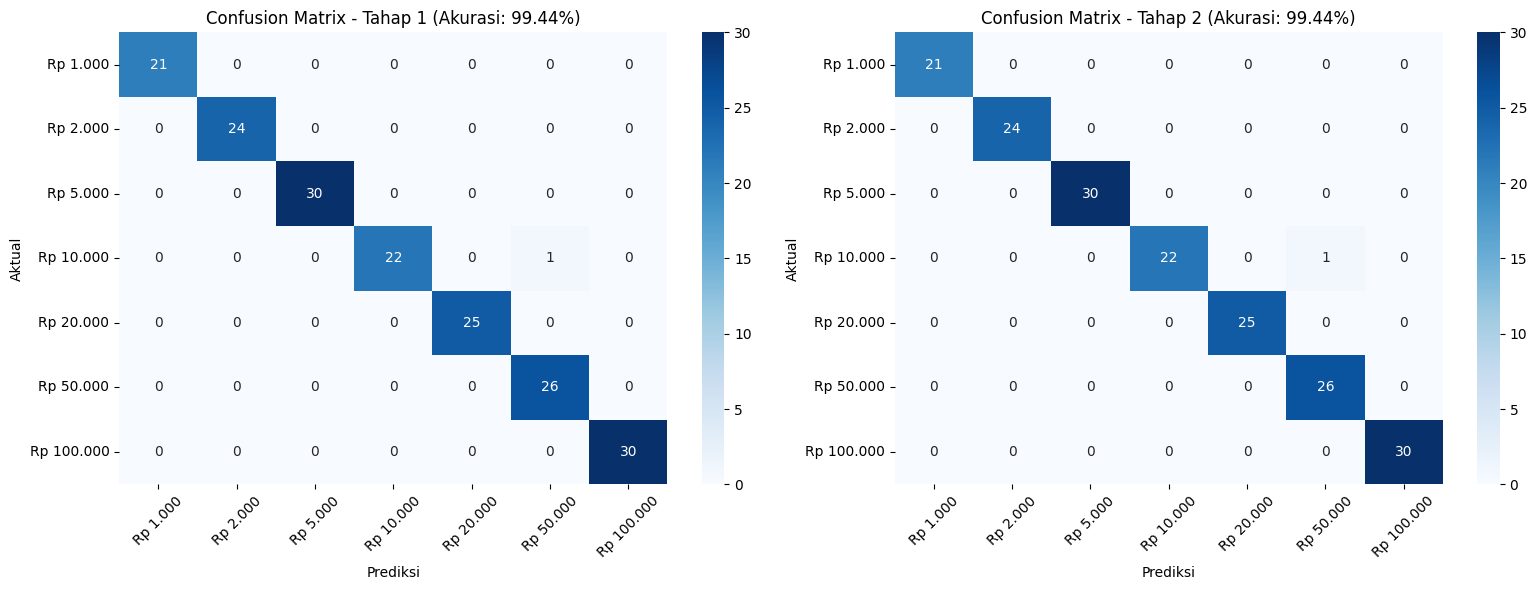

Dua Confusion Matrix (Tahap 1 vs Tahap 2) berhasil ditampilkan.


In [18]:
cm_t1 = confusion_matrix(y_true, pred_frozen)
cm_t2 = confusion_matrix(y_true, pred_ft)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Confusion Matrix Tahap 1
sns.heatmap(cm_t1, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=target_names, yticklabels=target_names)
axes[0].set_title(f'Confusion Matrix - Tahap 1 (Akurasi: {acc_t1*100:.2f}%)')
axes[0].set_ylabel('Aktual')
axes[0].set_xlabel('Prediksi')
axes[0].tick_params(axis='x', rotation=45)

# Confusion Matrix Tahap 2
sns.heatmap(cm_t2, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=target_names, yticklabels=target_names)
axes[1].set_title(f'Confusion Matrix - Tahap 2 (Akurasi: {acc_t2*100:.2f}%)')
axes[1].set_ylabel('Aktual')
axes[1].set_xlabel('Prediksi')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()
print('Dua Confusion Matrix (Tahap 1 vs Tahap 2) berhasil ditampilkan.')


## 10. Simpan Model Final


In [ ]:
model_ft.save(FINAL_MODEL_PATH)
print('Model final berhasil disimpan ke:', FINAL_MODEL_PATH)

print('\n=== Ringkasan File Model yang Disimpan ===')
saved_items = [
    {
        'Nama File': 'efficientnetv2_frozen.keras',
        'Ukuran': f"{os.path.getsize(MODEL_SAVE_PATH)/(1024*1024):.2f} MB" if os.path.exists(MODEL_SAVE_PATH) else '-',
        'Tahapan': 'Tahap 1 (Backbone Frozen)',
        'Deskripsi / Kegunaan': 'Checkpoint bobot terbaik saat hanya classifier head yang dilatih'
    },
    {
        'Nama File': 'efficientnetv2_finetuned.keras',
        'Ukuran': f"{os.path.getsize(FINETUNE_SAVE_PATH)/(1024*1024):.2f} MB" if os.path.exists(FINETUNE_SAVE_PATH) else '-',
        'Tahapan': 'Tahap 2 (Fine-Tuning)',
        'Deskripsi / Kegunaan': 'Checkpoint bobot terbaik selama proses fine-tuning'
    },
    {
        'Nama File': 'efficientnetv2_rupiah.keras',
        'Ukuran': f"{os.path.getsize(FINAL_MODEL_PATH)/(1024*1024):.2f} MB" if os.path.exists(FINAL_MODEL_PATH) else '-',
        'Tahapan': 'Model Final (Deployment)',
        'Deskripsi / Kegunaan': 'Model siap pakai untuk inferensi backend API dan aplikasi'
    }
]

df_saved = pd.DataFrame(saved_items)
display(df_saved)


Model final berhasil disimpan ke: C:\DL\rupiah-detector\models\efficientnetv2_rupiah.keras

=== Ringkasan File Model yang Disimpan ===


,Nama File,Ukuran,Tahapan,Deskripsi / Kegunaan
0,efficientnetv2_frozen.keras,27.31 MB,Tahap 1 (Backbone Frozen),Checkpoint bobot terbaik saat hanya classifier...
1,efficientnetv2_finetuned.keras,40.36 MB,Tahap 2 (Fine-Tuning),Checkpoint bobot terbaik selama proses fine-tu...
2,efficientnetv2_rupiah.keras,40.35 MB,Model Final (Deployment),Model siap pakai untuk inferensi backend API d...
